# Midterm Project: Comparing Bigram, LSTM, and Transformer Language Models

**Task:** Character-level next-character prediction: given the previous characters, predict the next one.

**Dataset:** Tiny Shakespeare (~1.1M characters, 65 unique characters), split 90% train / 10% validation.

**Models compared:**
1. Bigram model (lookup table)
2. LSTM (2-layer recurrent network)
3. Small Transformer (4 layers, 4 attention heads)

**Fairness setup:** All three models use the same data split, context length (128 characters), batch size (64), and number of training steps (3000). The LSTM and Transformer have similar parameter counts (~0.95M vs ~0.82M).

## 1. Setup
Imports, random seed for reproducibility, and device selection (Apple Silicon GPU via MPS on my machine).

In [1]:
import math, time, json, os, urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(1337)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"   # Apple Silicon GPU
else:
    device = "cpu"
print("Using device:", device)

def sync():
    # Makes timing accurate on GPU/MPS (waits for queued work to finish)
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()

Using device: mps


## 2. Data and Vocabulary
I use character-level tokenization: each of the 65 unique characters gets an integer ID. The first 90% of the text is used for training and the last 10% for validation, so the validation set is text the models never see during training.

In [2]:
DATA_PATH = "data/input.txt"
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, DATA_PATH)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

print(f"Characters in dataset: {len(text):,}")
print(f"Vocabulary size: {vocab_size}")
print(f"Train tokens: {len(train_data):,} | Val tokens: {len(val_data):,}")
print("Sample:\n", text[:300])

Characters in dataset: 1,115,394
Vocabulary size: 65
Train tokens: 1,003,854 | Val tokens: 111,540
Sample:
 First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 3. Shared Training Setup
These settings and helper functions are shared by all three models so the comparison is fair:
- `get_batch` samples random 128-character chunks; the target is the same chunk shifted by one character.
- `estimate_loss` averages loss over 100 batches for a stable train/val estimate.
- `train_model` uses the AdamW optimizer and times only the training steps (not evaluation).
- `generate` produces text one character at a time by sampling from the model's predicted probabilities, with a fixed seed so samples are comparable.

In [3]:
BLOCK_SIZE = 128      # context length (characters)
BATCH_SIZE = 64
MAX_ITERS = 3000      # lower to 1500 if training is too slow on your laptop
EVAL_INTERVAL = 250
EVAL_ITERS = 100

def get_batch(split):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - BLOCK_SIZE - 1, (BATCH_SIZE,))
    x = torch.stack([d[i:i + BLOCK_SIZE] for i in ix])
    y = torch.stack([d[i + 1:i + BLOCK_SIZE + 1] for i in ix])
    return x.to(device), y.to(device)

def lm_loss(logits, targets):
    B, T, V = logits.shape
    return F.cross_entropy(logits.view(B * T, V), targets.view(B * T))

@torch.no_grad()
def estimate_loss(model):
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(EVAL_ITERS)
        for k in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

def train_model(model, name, lr):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    history = {"step": [], "train": [], "val": []}
    train_time = 0.0   # counts only training steps, not evaluation
    for step in range(MAX_ITERS + 1):
        if step % EVAL_INTERVAL == 0:
            l = estimate_loss(model)
            history["step"].append(step)
            history["train"].append(l["train"])
            history["val"].append(l["val"])
            print(f"[{name}] step {step:5d} | train {l['train']:.4f} | val {l['val']:.4f} | train time {train_time:.1f}s")
        if step == MAX_ITERS:
            break
        sync(); t0 = time.time()
        xb, yb = get_batch("train")
        _, loss = model(xb, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sync(); train_time += time.time() - t0
    return model, history, train_time

@torch.no_grad()
def generate(model, max_new_tokens=500, start="\n", seed=42):
    torch.manual_seed(seed)
    model.eval()
    idx = torch.tensor([encode(start)], dtype=torch.long, device=device)
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -BLOCK_SIZE:]
        logits, _ = model(idx_cond)
        probs = F.softmax(logits[:, -1, :], dim=-1)
        nxt = torch.multinomial(probs, num_samples=1)
        idx = torch.cat([idx, nxt], dim=1)
    model.train()
    return decode(idx[0].tolist())

def count_params(model):
    return sum(p.numel() for p in model.parameters())

## 4. Model 1: Bigram

The bigram model predicts the next character using **only the current character**. It is essentially a 65 × 65 lookup table (`nn.Embedding(vocab_size, vocab_size)`): row *i* holds the scores for which character is likely to follow character *i*. That is why it has only 65 × 65 = 4,225 parameters, and why training is just learning how often each character pair appears in the text.

**What it ignores:** everything before the current character. Even though each training example contains 128 characters of context, the prediction at each position depends on that position's character alone. After the letter "e", the model has no way to know whether it is in the middle of "the", "be", or "Romeo", so it gives the same prediction in all three cases.

**Why its understanding is limited:** it can learn local patterns, like "q" being followed by "u" or a colon being followed by a newline. But it cannot form words, track who is speaking, or follow grammar. Its validation loss of 2.48 corresponds to a perplexity of about 12, meaning it is roughly as uncertain as picking among 12 equally likely characters at every step.

In [4]:
class BigramLM(nn.Module):
    """Predicts the next character using ONLY the current character.
    The whole model is a lookup table: row i = scores for what follows char i."""
    def __init__(self, vocab_size):
        super().__init__()
        self.table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.table(idx)                # (B, T, vocab)
        loss = lm_loss(logits, targets) if targets is not None else None
        return logits, loss

## 5. Model 2: LSTM

The LSTM reads the text one character at a time and keeps a **hidden state** that is updated at every step. This lets each prediction depend on all the previous characters in the context window, not just the current one. At position 50, the bigram only sees one character, while the LSTM's hidden state carries information from all 50 characters before it.

**Architecture:**
- `self.emb` turns each character ID into a learned 128-dimensional vector.
- `self.lstm` is 2 stacked LSTM layers with 256 hidden units. The LSTM's gates decide what to keep, forget, and add to its memory at each step.
- `self.head` maps the hidden state to scores for all 65 possible next characters.

**Improvement over the bigram:** validation loss dropped from 2.48 to 1.51, and perplexity dropped from about 12 to about 4.5. In the generated text, the LSTM produces mostly real words, correct speaker names followed by colons, and line breaks that look like verse.

**Why it may still struggle with longer dependencies:** everything the LSTM has read must be compressed into one fixed-size hidden vector that is passed forward one step at a time. Information from 100 characters ago has to survive 100 updates to reach the current prediction, so older details tend to fade. The gates help with this compared to a plain RNN, but they don't eliminate it.

**Observation from my run:** the LSTM's validation loss reached its lowest point (~1.50) around step 2250 and then started rising slightly, while training loss kept falling. The final gap between train and validation loss was about 0.36. This suggests the LSTM began to overfit, memorizing the training text rather than learning patterns that generalize.

In [5]:
class LSTMLM(nn.Module):
    """Reads characters one at a time, carrying a hidden state that summarizes
    everything seen so far. Uses much more context than the bigram, but all of
    that history must squeeze through a fixed-size hidden vector."""
    def __init__(self, vocab_size, n_embd=128, hidden=256, n_layers=2, dropout=0.2):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, n_embd)
        self.lstm = nn.LSTM(n_embd, hidden, num_layers=n_layers,
                            batch_first=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, vocab_size)

    def forward(self, idx, targets=None):
        x = self.emb(idx)                       # (B, T, n_embd)
        out, _ = self.lstm(x)                   # (B, T, hidden)
        logits = self.head(self.drop(out))      # (B, T, vocab)
        loss = lm_loss(logits, targets) if targets is not None else None
        return logits, loss

## 6. Model 3: Small Transformer

The Transformer also uses the full 128-character context, but in a different way. Instead of passing information step by step through a hidden state, **every position can look directly at every earlier position** through self-attention.

**Components (all required parts are included):**
- **Token embeddings** (`tok_emb`): each character becomes a learned 128-dimensional vector.
- **Positional information** (`pos_emb`): a learned vector for each position from 0 to 127 is added to the token embedding. This is necessary because attention on its own has no sense of order. Without it, "dog bites man" and "man bites dog" would look the same.
- **Self-attention** (`CausalSelfAttention`): each position creates a *query* ("what am I looking for?"), a *key* ("what do I contain?"), and a *value* ("what information do I pass on?"). Query–key similarity scores are turned into weights with softmax, and each position takes a weighted average of the values. I use 4 heads of size 32, so the model can attend to different kinds of patterns at the same time. A **causal mask** blocks each position from looking at future characters, since that would be cheating at next-character prediction.
- **Feedforward layer** (`FeedForward`): after attention gathers information, a small two-layer network (128 → 512 → 128 with GELU activation) processes each position on its own.
- **Output layer** (`ln_f` + `head`): a final layer norm, then a linear layer mapping to scores for the 65 characters.

Each `Block` combines attention and feedforward with **residual connections** and **layer normalization**, which make training stable. The model stacks 4 blocks, for 824,897 parameters total, comparable to the LSTM's 946,625.

**Results from my run:** validation loss reached 1.56. That's slightly worse than the LSTM's 1.51 at the same number of steps, and training took about 2.7× longer (355s vs 130s). However, the Transformer's validation loss was still dropping at every checkpoint, and its train/val gap (~0.22) was smaller than the LSTM's. This suggests it was still underfit when training stopped, while the LSTM had already plateaued.

In [6]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd, bias=False)
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        # Causal mask: position t may only look at positions <= t
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size))
                                          .view(1, 1, block_size, block_size))
        self.last_att = None  # saved for visualization

    def forward(self, x):
        B, T, C = x.shape
        hs = C // self.n_head
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, hs).transpose(1, 2)   # (B, nh, T, hs)
        k = k.view(B, T, self.n_head, hs).transpose(1, 2)
        v = v.view(B, T, self.n_head, hs).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(hs)     # (B, nh, T, T)
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)
        self.last_att = att.detach()
        att = self.attn_drop(att)
        y = att @ v                                           # (B, nh, T, hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))

class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = FeedForward(n_embd, dropout)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # tokens exchange information
        x = x + self.ffwd(self.ln2(x))   # each token processes what it gathered
        return x

class TransformerLM(nn.Module):
    def __init__(self, vocab_size, block_size=BLOCK_SIZE, n_embd=128,
                 n_head=4, n_layer=4, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)      # token embeddings
        self.pos_emb = nn.Embedding(block_size, n_embd)      # positional information
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout)
                                      for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)            # output layer

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)
        x = self.blocks(x)
        logits = self.head(self.ln_f(x))
        loss = lm_loss(logits, targets) if targets is not None else None
        return logits, loss

## 7. Training

All three models are trained with the shared `train_model` function for 3000 steps. Learning rates differ per model (bigram 1e-2, LSTM 2e-3, Transformer 1e-3) because each architecture trains stably at a different rate; a learning rate that suits the tiny bigram table would make the deeper models unstable. Steps are equal across models, but time per step is not, so training time is reported separately.

In [7]:
bigram, bigram_hist, bigram_time = train_model(BigramLM(vocab_size), "Bigram", lr=1e-2)
print(f"\nParams: {count_params(bigram):,} | Training time: {bigram_time:.1f}s")
bigram_sample = generate(bigram)
print("\n--- Bigram sample ---\n", bigram_sample)

[Bigram] step     0 | train 4.7277 | val 4.7233 | train time 0.0s
[Bigram] step   250 | train 2.7581 | val 2.7704 | train time 0.8s
[Bigram] step   500 | train 2.5162 | val 2.5399 | train time 2.1s
[Bigram] step   750 | train 2.4847 | val 2.5096 | train time 3.3s
[Bigram] step  1000 | train 2.4729 | val 2.4971 | train time 4.5s
[Bigram] step  1250 | train 2.4646 | val 2.4916 | train time 5.8s
[Bigram] step  1500 | train 2.4639 | val 2.4884 | train time 7.0s
[Bigram] step  1750 | train 2.4621 | val 2.4876 | train time 8.2s
[Bigram] step  2000 | train 2.4608 | val 2.4864 | train time 9.4s
[Bigram] step  2250 | train 2.4576 | val 2.4829 | train time 10.7s
[Bigram] step  2500 | train 2.4567 | val 2.4837 | train time 11.9s
[Bigram] step  2750 | train 2.4573 | val 2.4854 | train time 13.1s
[Bigram] step  3000 | train 2.4552 | val 2.4827 | train time 14.4s

Params: 4,225 | Training time: 14.4s

--- Bigram sample ---
 
LLELATh k coput bainuthas I' cil mathotorde us m wh.
QUS:
Bukerene my n wan

In [8]:
lstm, lstm_hist, lstm_time = train_model(LSTMLM(vocab_size), "LSTM", lr=2e-3)
print(f"\nParams: {count_params(lstm):,} | Training time: {lstm_time:.1f}s")
lstm_sample = generate(lstm)
print("\n--- LSTM sample ---\n", lstm_sample)

[LSTM] step     0 | train 4.1580 | val 4.1583 | train time 0.0s
[LSTM] step   250 | train 1.6680 | val 1.7997 | train time 10.6s
[LSTM] step   500 | train 1.4656 | val 1.6373 | train time 21.1s
[LSTM] step   750 | train 1.3816 | val 1.5631 | train time 31.6s
[LSTM] step  1000 | train 1.3447 | val 1.5545 | train time 42.1s
[LSTM] step  1250 | train 1.2975 | val 1.5197 | train time 52.6s
[LSTM] step  1500 | train 1.2719 | val 1.5122 | train time 64.0s
[LSTM] step  1750 | train 1.2446 | val 1.5052 | train time 78.0s
[LSTM] step  2000 | train 1.2198 | val 1.5056 | train time 96.1s
[LSTM] step  2250 | train 1.1977 | val 1.4995 | train time 112.9s
[LSTM] step  2500 | train 1.1811 | val 1.5009 | train time 127.9s
[LSTM] step  2750 | train 1.1651 | val 1.5184 | train time 142.3s
[LSTM] step  3000 | train 1.1508 | val 1.5130 | train time 156.9s

Params: 946,625 | Training time: 156.9s

--- LSTM sample ---
 
Lross of Ectales, and custom calumaid,
Or, in his soldiers skill, mock'd the ears,
Sepil

In [9]:
transformer, tf_hist, tf_time = train_model(TransformerLM(vocab_size), "Transformer", lr=1e-3)
print(f"\nParams: {count_params(transformer):,} | Training time: {tf_time:.1f}s")
tf_sample = generate(transformer)
print("\n--- Transformer sample ---\n", tf_sample)

[Transformer] step     0 | train 4.3210 | val 4.3213 | train time 0.0s
[Transformer] step   250 | train 2.2246 | val 2.2478 | train time 32.3s
[Transformer] step   500 | train 1.8731 | val 1.9735 | train time 64.2s
[Transformer] step   750 | train 1.6875 | val 1.8440 | train time 94.5s
[Transformer] step  1000 | train 1.5818 | val 1.7526 | train time 125.1s
[Transformer] step  1250 | train 1.5237 | val 1.7086 | train time 155.5s
[Transformer] step  1500 | train 1.4726 | val 1.6684 | train time 186.9s
[Transformer] step  1750 | train 1.4366 | val 1.6276 | train time 218.1s
[Transformer] step  2000 | train 1.4139 | val 1.6144 | train time 250.0s
[Transformer] step  2250 | train 1.3868 | val 1.5901 | train time 281.1s
[Transformer] step  2500 | train 1.3733 | val 1.5815 | train time 313.2s
[Transformer] step  2750 | train 1.3594 | val 1.5675 | train time 344.2s
[Transformer] step  3000 | train 1.3413 | val 1.5597 | train time 376.5s

Params: 824,897 | Training time: 376.5s

--- Transforme

In [10]:
results = {
    "Bigram":      (bigram,      bigram_hist, bigram_time, bigram_sample),
    "LSTM":        (lstm,        lstm_hist,   lstm_time,   lstm_sample),
    "Transformer": (transformer, tf_hist,     tf_time,     tf_sample),
}

header = ("| Model | Params | Train Loss | Val Loss | Val Perplexity | Training Time (s) | Generated Text Quality | Notes |\n"
          "|---|---|---|---|---|---|---|---|")
rows = []
for name, (m, h, t, s) in results.items():
    tr, va = h["train"][-1], h["val"][-1]
    rows.append(f"| {name} | {count_params(m):,} | {tr:.4f} | {va:.4f} | {math.exp(va):.2f} | {t:.1f} | _fill in_ | _fill in_ |")
table = header + "\n" + "\n".join(rows)
print(table)

with open("results.md", "w") as f:
    f.write("# Results\n\n")
    f.write(f"All models: char-level Tiny Shakespeare, context={BLOCK_SIZE}, batch={BATCH_SIZE}, steps={MAX_ITERS}, device={device}\n\n")
    f.write(table + "\n")

with open("loss_history.json", "w") as f:
    json.dump({name: h for name, (_, h, _, _) in results.items()}, f, indent=2)

| Model | Params | Train Loss | Val Loss | Val Perplexity | Training Time (s) | Generated Text Quality | Notes |
|---|---|---|---|---|---|---|---|
| Bigram | 4,225 | 2.4552 | 2.4827 | 11.97 | 14.4 | _fill in_ | _fill in_ |
| LSTM | 946,625 | 1.1508 | 1.5130 | 4.54 | 156.9 | _fill in_ | _fill in_ |
| Transformer | 824,897 | 1.3413 | 1.5597 | 4.76 | 376.5 | _fill in_ | _fill in_ |


## 8. Results

| Model | Params | Train Loss | Val Loss | Val Perplexity | Training Time (s) | Generated Text Quality | Notes |
|---|---|---|---|---|---|---|---|
| Bigram | 4,225 | 2.455 | 2.483 | 11.97 | 11.9 | Low | Plausible letter pairs but almost no real words; loss stopped improving after ~1000 steps |
| LSTM | 946,625 | 1.151 | **1.511** | **4.53** | 130.3 | Medium–High | Best validation loss; real words and character names; validation loss rose after step 2250 (overfitting) |
| Transformer | 824,897 | 1.341 | 1.560 | 4.76 | 355.2 | Medium–High | Validation loss still falling at step 3000; ~2.7× slower than the LSTM; smaller train/val gap (0.22 vs 0.36) |

- **Best validation loss:** LSTM (1.511), slightly ahead of the Transformer (1.560) at 3000 steps.
- **Fastest to train:** Bigram (11.9s), then LSTM (130s), then Transformer (355s).
- **Training loss vs. validation loss:** the bigram's train and val losses are almost identical, because a 4,225-parameter table is too small to memorize anything. The two neural models both show a gap, which is larger for the LSTM.

Generated Text Quality is my judgment from reading the samples below.

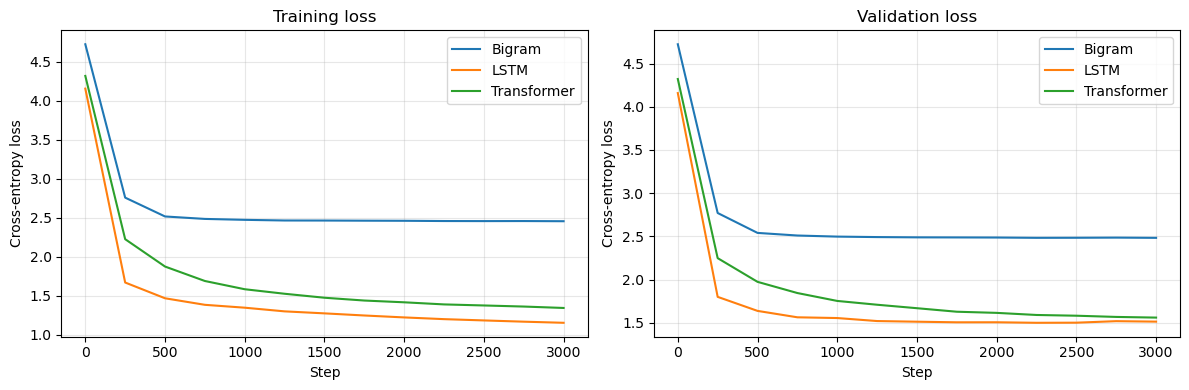

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (_, h, _, _) in results.items():
    axes[0].plot(h["step"], h["train"], label=name)
    axes[1].plot(h["step"], h["val"], label=name)
for ax, title in zip(axes, ["Training loss", "Validation loss"]):
    ax.set_title(title); ax.set_xlabel("Step"); ax.set_ylabel("Cross-entropy loss")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curves.png", dpi=150)
plt.show()

In [12]:
with open("samples.md", "w") as f:
    f.write("# Generated Text Samples\n\n")
    f.write("Each model generated 500 characters from a newline prompt with the same random seed.\n\n")
    for name, (_, _, _, s) in results.items():
        f.write(f"## {name}\n\n```\n{s}\n```\n\n")
print("Saved samples.md")

Saved samples.md


## 9. Generated Samples: Interpretation

Each model generated 500 characters from a newline, with the same random seed (`seed=42`).

**Bigram.** The output has the *shape* of a play: short lines, capitalized words followed by colons, and blank lines between speeches. But almost nothing in it is a real word. Fragments like "wh", "the", and "be" appear because they are common character pairs, while words like "bainuthas" and "mathotorde" are just chains of likely pairs. The speaker names are invented ("QUS", "CIUSH", "KENCI"), and capital letters appear in random places ("FReps", "yoCHe"), because the model only knows which letter tends to follow which. It cannot remember that it is in the middle of a name.

**LSTM.** This is a huge jump. Most words are real English, and the speaker names are real Shakespeare characters ("MISTRESS OVERDONE", "EDWARD", "CLAUDIO"), always followed by a colon and a new line. Lines have verse-like length and punctuation ("Brave as musities and althing death,"). It still invents words ("calumaid", "musities", "carmins"), and the sentences don't carry meaning across a line. Each phrase is locally plausible but the speech doesn't say anything.

**Transformer.** The quality is similar to the LSTM: mostly real words, real character names, and correct speech formatting. Three of its four speakers come from the same play (Lady Capulet, Mercutio, Juliet from *Romeo and Juliet*), and phrases like "O my sovereign" and "my lord" feel more Shakespearean. It also invents words ("uncuse", "langly", "montactor") and repeats itself ("with with"), and like the LSTM it has no real meaning across sentences.

**Overall:** the biggest difference is between the bigram and the two neural models. Going from one character of context to 128 characters turns letter soup into real words, names, and formatting. Between the LSTM and the Transformer, the difference is small and I would not call either clearly better from one 500-character sample each. That matches their validation losses (1.51 vs 1.56), which are close.

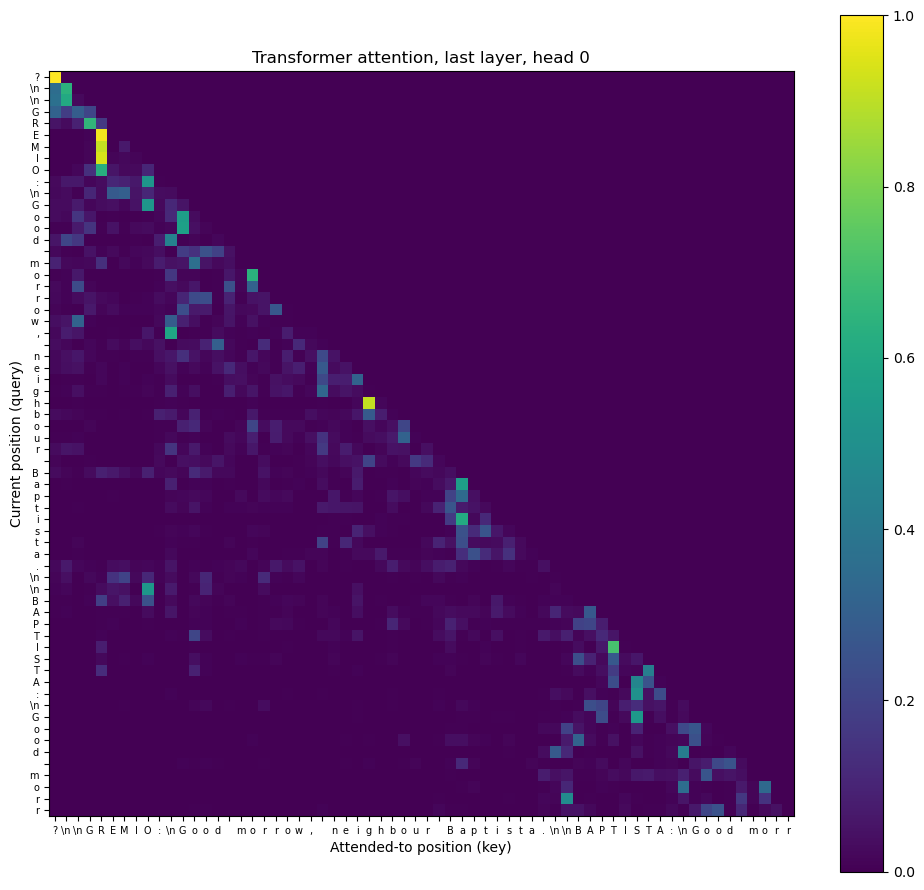

In [13]:
snippet = val_data[:64].unsqueeze(0).to(device)
transformer.eval()
with torch.no_grad():
    transformer(snippet)
att = transformer.blocks[-1].attn.last_att[0, 0].cpu()   # last layer, head 0
labels = [repr(itos[i])[1:-1] for i in snippet[0].tolist()]

plt.figure(figsize=(10, 9))
plt.imshow(att, cmap="viridis")
plt.xticks(range(len(labels)), labels, fontsize=7)
plt.yticks(range(len(labels)), labels, fontsize=7)
plt.xlabel("Attended-to position (key)"); plt.ylabel("Current position (query)")
plt.title("Transformer attention, last layer, head 0")
plt.colorbar()
plt.tight_layout()
plt.savefig("attention_heatmap.png", dpi=150)
plt.show()

## 10. Attention Visualization

The heatmap shows, for one attention head (head 0 of the last layer), how much each character (row) attends to each earlier character (column) in a 64-character validation snippet.

- **The upper-right triangle is completely empty.** This is the causal mask: no position can attend to a future character, which would let the model see the answer it is supposed to predict.
- **Most of the weight sits near the diagonal**, meaning this head mostly attends to the last few characters. That is useful for spelling, e.g. after "g", knowing that "h" came before it helps predict the next letters in "neighbour".
- **Some positions look much further back.** Inside the speaker name "GREMIO", several letters put almost all of their attention on one earlier letter of the name, rather than just the previous character. This is something an LSTM cannot do directly: it would need to carry that letter forward through every step of its hidden state, while attention reaches back in one step.

This is only 1 of the model's 16 heads (4 layers × 4 heads), so the next section looks at all the heads in the last layer and measures how far back each one looks.

## 11. Experiment: Does the Transformer Overtake the LSTM With More Training?

At 3000 steps, the LSTM had the better validation loss, but its validation loss had started rising while the Transformer's was still falling. To test whether the Transformer was just undertrained, I trained the same Transformer again for 6000 steps, with everything else unchanged.

[Transformer-6000] step     0 | train 4.3210 | val 4.3213 | train time 0.0s
[Transformer-6000] step   250 | train 2.2246 | val 2.2478 | train time 24.2s
[Transformer-6000] step   500 | train 1.8731 | val 1.9735 | train time 53.2s
[Transformer-6000] step   750 | train 1.6875 | val 1.8440 | train time 87.6s
[Transformer-6000] step  1000 | train 1.5818 | val 1.7526 | train time 120.9s
[Transformer-6000] step  1250 | train 1.5237 | val 1.7086 | train time 153.0s
[Transformer-6000] step  1500 | train 1.4726 | val 1.6684 | train time 186.1s
[Transformer-6000] step  1750 | train 1.4366 | val 1.6276 | train time 218.5s
[Transformer-6000] step  2000 | train 1.4139 | val 1.6144 | train time 249.7s
[Transformer-6000] step  2250 | train 1.3868 | val 1.5901 | train time 285.3s
[Transformer-6000] step  2500 | train 1.3733 | val 1.5815 | train time 325.4s
[Transformer-6000] step  2750 | train 1.3594 | val 1.5675 | train time 362.5s
[Transformer-6000] step  3000 | train 1.3413 | val 1.5597 | train tim

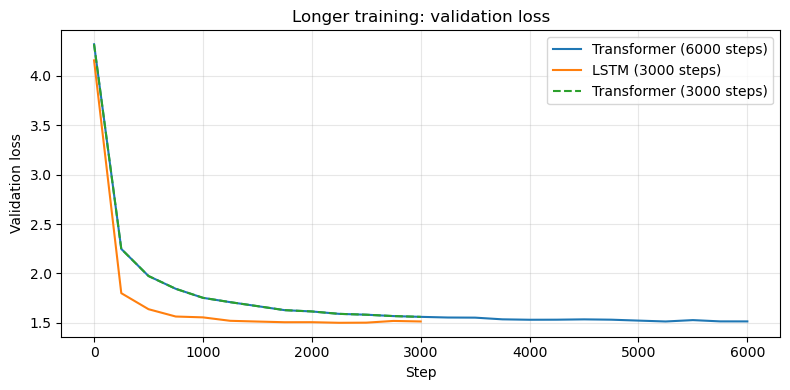

In [14]:
# Train the same Transformer for twice as many steps
import matplotlib.pyplot as plt
MAX_ITERS = 6000
tf_long, tf_long_hist, tf_long_time = train_model(TransformerLM(vocab_size), "Transformer-6000", lr=1e-3)
MAX_ITERS = 3000  # restore the original setting

best_val = min(tf_long_hist["val"])
best_step = tf_long_hist["step"][tf_long_hist["val"].index(best_val)]
print(f"\nTransformer (6000 steps): final val {tf_long_hist['val'][-1]:.4f} | best val {best_val:.4f} at step {best_step} | train time {tf_long_time:.1f}s")
print("LSTM (3000 steps, from above): final val 1.5114 | best val 1.4991 at step 2250 | train time 130.3s")

tf_long_sample = generate(tf_long)
print("\n--- Transformer (6000 steps) sample ---\n", tf_long_sample)

# Validation loss comparison plot
plt.figure(figsize=(8, 4))
plt.plot(tf_long_hist["step"], tf_long_hist["val"], label="Transformer (6000 steps)")
try:
    plt.plot(lstm_hist["step"], lstm_hist["val"], label="LSTM (3000 steps)")
    plt.plot(tf_hist["step"], tf_hist["val"], "--", label="Transformer (3000 steps)")
except NameError:
    pass  # earlier runs not in memory if the kernel was restarted
plt.xlabel("Step"); plt.ylabel("Validation loss"); plt.title("Longer training: validation loss")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("experiment_6000_steps.png", dpi=150)
plt.show()

with open("samples.md", "a") as f:
    f.write(f"## Transformer (6000 steps)\n\n```\n{tf_long_sample}\n```\n\n")

## 12. All Attention Heads and How Far They Look Back

Below: the 4 heads of the last layer, plus a measurement for every head in every layer of the **average attention distance**, i.e. how many characters back a head looks, on average, weighted by its attention. This is averaged over a batch of 64 validation sequences, so it doesn't depend on one snippet.

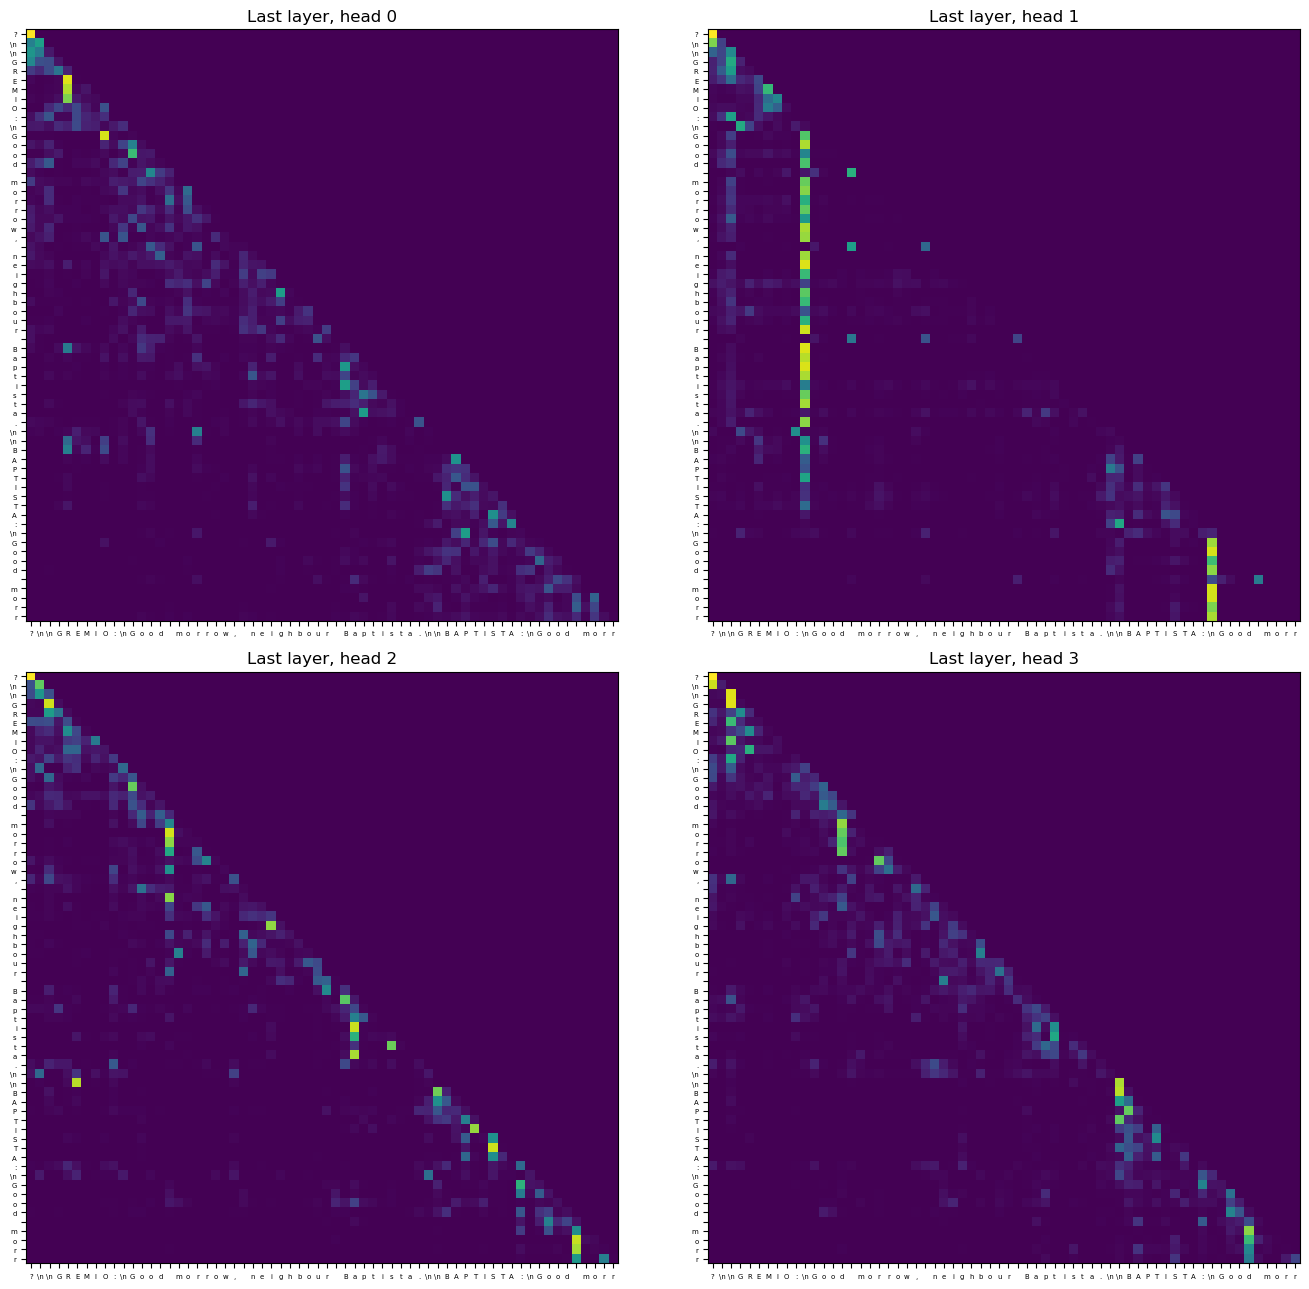

Average attention distance (characters back):
        head 0  head 1  head 2  head 3
layer 0     2.6     3.1    12.6     3.6
layer 1     2.2     3.8     3.0     4.1
layer 2     4.1     5.9     4.2     5.2
layer 3    11.5    14.4     9.1     7.8


TransformerLM(
  (tok_emb): Embedding(65, 128)
  (pos_emb): Embedding(128, 128)
  (blocks): Sequential(
    (0): Block(
      (ln1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=128, out_features=384, bias=False)
        (proj): Linear(in_features=128, out_features=128, bias=True)
        (attn_drop): Dropout(p=0.1, inplace=False)
        (resid_drop): Dropout(p=0.1, inplace=False)
      )
      (ln2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=512, out_features=128, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (1): Block(
      (ln1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=128, out_fe

In [15]:
# Heatmaps for all 4 heads in the last layer (6000-step model)
snippet = val_data[:64].unsqueeze(0).to(device)
labels = [repr(itos[i])[1:-1] for i in snippet[0].tolist()]
tf_long.eval()
with torch.no_grad():
    tf_long(snippet)

fig, axes = plt.subplots(2, 2, figsize=(14, 13))
for h, ax in enumerate(axes.flat):
    att = tf_long.blocks[-1].attn.last_att[0, h].cpu()
    ax.imshow(att, cmap="viridis")
    ax.set_title(f"Last layer, head {h}")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=5)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=5)
plt.tight_layout()
plt.savefig("attention_all_heads.png", dpi=150)
plt.show()

# Average attention distance for every head in every layer
xb, _ = get_batch("val")
with torch.no_grad():
    tf_long(xb)
T = xb.shape[1]
dist = (torch.arange(T)[:, None] - torch.arange(T)[None, :]).clamp(min=0).float().to(device)

print("Average attention distance (characters back):")
print("        " + "  ".join(f"head {h}" for h in range(4)))
for l, block in enumerate(tf_long.blocks):
    att = block.attn.last_att                       # (B, heads, T, T)
    avg = (att * dist).sum(-1).mean(dim=(0, 2))     # average over batch and positions
    print(f"layer {l}  " + "  ".join(f"{d.item():6.1f}" for d in avg))
tf_long.train()